
# Hong Kong Traffic Accident Severity: Model and Visualization

This notebook continues the existing data cleaning and exploratory analysis.

- Unit of analysis: recorded traffic accident
- Target: severe outcome (`Fatal` or `Serious`) versus `Slight`
- Model development: 2024 data only
- Independent temporal test: 2025 data
- Interpretation: predictive associations, not causal effects or real-time early warning

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import catboost

from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

DATA_DIR = Path("converted_xlsx")
OUTPUT_DIR = Path("proposal_analysis") / "model_visualization_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

assert (DATA_DIR / "24pubdb.xlsx").exists()
assert (DATA_DIR / "25pubdb.xlsx").exists()
assert (DATA_DIR / "24codee.xlsx").exists()
assert (DATA_DIR / "25codee.xlsx").exists()

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("catboost:", catboost.__version__)
print("Output directory:", OUTPUT_DIR)

pandas: 1.5.3
scikit-learn: 1.5.1
catboost: 1.2.10
Output directory: proposal_analysis\model_visualization_outputs


In [2]:

def load_year_tables(year):
    file_path = DATA_DIR / f"{str(year)[-2:]}pubdb.xlsx"

    accident = pd.read_excel(
        file_path,
        sheet_name=f"accident{year}",
        keep_default_na=False
    )

    vehicle = pd.read_excel(
        file_path,
        sheet_name=f"vehicle{year}",
        keep_default_na=False
    )

    accident = accident.replace(r"^\s*$", np.nan, regex=True)
    vehicle = vehicle.replace(r"^\s*$", np.nan, regex=True)

    return accident, vehicle


accident24_raw, vehicle24_raw = load_year_tables(2024)
accident25_raw, vehicle25_raw = load_year_tables(2025)

shape_check = pd.DataFrame({
    "table": [
        "2024 accident", "2024 vehicle",
        "2025 accident", "2025 vehicle"
    ],
    "rows": [
        len(accident24_raw), len(vehicle24_raw),
        len(accident25_raw), len(vehicle25_raw)
    ],
    "columns": [
        accident24_raw.shape[1], vehicle24_raw.shape[1],
        accident25_raw.shape[1], vehicle25_raw.shape[1]
    ]
})

display(shape_check)

,table,rows,columns
0,2024 accident,18354,13
1,2024 vehicle,31315,6
2,2025 accident,17320,13
3,2025 vehicle,29595,6


In [3]:
def normalize_code(value):
    if pd.isna(value):
        return None

    text = str(value).strip()

    try:
        number = float(text)
        if np.isfinite(number) and number.is_integer():
            return str(int(number))
    except ValueError:
        pass

    return text


def load_codebook_mappings(year, sheet_name):
    codebook_path = DATA_DIR / f"{str(year)[-2:]}codee.xlsx"

    codebook = pd.read_excel(
        codebook_path,
        sheet_name=sheet_name,
        keep_default_na=False
    )

    codebook["Field name"] = (
        codebook["Field name"]
        .replace(r"^\s*$", np.nan, regex=True)
        .ffill()
    )

    codebook = codebook[
        codebook["Code"].astype(str).str.strip().ne("")
    ].copy()

    mappings = {}

    for field_name, group in codebook.groupby("Field name"):
        mappings[field_name] = {
            normalize_code(code): str(description).strip()
            for code, description in zip(
                group["Code"],
                group["Description"]
            )
        }

    return mappings


accident_maps24 = load_codebook_mappings(2024, "Accident")
vehicle_maps24 = load_codebook_mappings(2024, "Vehicle")
accident_maps25 = load_codebook_mappings(2025, "Accident")
vehicle_maps25 = load_codebook_mappings(2025, "Vehicle")

print("Severity mapping:", accident_maps24["Severity of Accident"])
print("Vehicle class mapping:", vehicle_maps24["Vehicle Class"])

Severity mapping: {'1': 'Fatal', '2': 'Serious', '3': 'Slight'}
Vehicle class mapping: {'1': 'Motorcycle', '2': 'Private car', '3': 'Public light bus', '4': 'Light goods vehicle', '5': 'Medium goods vehicle', '6': 'Heavy goods vehicle', '7': 'Franchised public bus', '8': 'Non-franchised public bus', '9': 'Taxi', '10': 'Bicycle', '11': 'Tram', '12': 'Light rail vehicle', '13': 'Others (incl. unknown)'}


In [4]:
def decode_selected_columns(frame, column_mappings):
    result = frame.copy()

    for column, mapping in column_mappings.items():
        normalized = result[column].map(normalize_code)
        unknown_codes = set(normalized.dropna()) - set(mapping)

        if unknown_codes:
            raise ValueError(
                f"Unknown codes in {column}: {sorted(unknown_codes)}"
            )

        result[column] = normalized.map(mapping).astype("string")

    return result


def prepare_year_data(year, accident_raw, vehicle_raw,
                      accident_maps, vehicle_maps):
    accident_mapping_spec = {
        "Severity": accident_maps["Severity of Accident"],
        "District Council District":
            accident_maps["District Council District"],
        "Hit and Run": accident_maps["Hit and Run"],
        "Weather": accident_maps["Weather"],
        "Rain": accident_maps["Rain"],
        "Natural Light": accident_maps["Natural Light"],
        "Junction Control": accident_maps["Junction Control"],
        "Road Classification":
            accident_maps["Road Classification"],
        "Vehicle Movements": accident_maps["Vehicle Movements"],
        "Type of Collision": accident_maps["Type of Collision"]
    }

    vehicle_mapping_spec = {
        "Driver Sex": vehicle_maps["Driver Sex"],
        "Vehicle Class": vehicle_maps["Vehicle Class"]
    }

    accident = decode_selected_columns(
        accident_raw,
        accident_mapping_spec
    )

    vehicle = decode_selected_columns(
        vehicle_raw,
        vehicle_mapping_spec
    )

    # Create the binary target.
    accident["severe"] = (
        accident["Severity"].isin(["Fatal", "Serious"])
    ).astype(int)

    # Convert special unknown values to missing values.
    vehicle["Driver Age"] = (
        pd.to_numeric(vehicle["Driver Age"], errors="coerce")
        .replace(999, np.nan)
    )

    vehicle["Year of Manufacture"] = pd.to_numeric(
        vehicle["Year of Manufacture"],
        errors="coerce"
    )

    vehicle["Vehicle Age"] = (
        year - vehicle["Year of Manufacture"]
    )

    vehicle.loc[
        (vehicle["Vehicle Age"] < 0)
        | (vehicle["Vehicle Age"] > 100),
        "Vehicle Age"
    ] = np.nan

    # Remove variables that directly reveal the accident outcome.
    accident = accident.drop(columns=["No. of Casualties"])
    vehicle = vehicle.drop(columns=["Severity of Accident"])

    return accident, vehicle


accident24, vehicle24 = prepare_year_data(
    2024,
    accident24_raw,
    vehicle24_raw,
    accident_maps24,
    vehicle_maps24
)

accident25, vehicle25 = prepare_year_data(
    2025,
    accident25_raw,
    vehicle25_raw,
    accident_maps25,
    vehicle_maps25
)

severity_check = pd.DataFrame({
    "2024": accident24["Severity"].value_counts(),
    "2025": accident25["Severity"].value_counts()
}).fillna(0).astype(int)

display(severity_check)
print("2024 vehicle columns:", vehicle24.columns.tolist())

,2024,2025
Slight,17520,16761
Serious,751,467
Fatal,83,92


2024 vehicle columns: ['Serial', 'Driver Age', 'Driver Sex', 'Year of Manufacture', 'Vehicle Class', 'Vehicle Age']


In [5]:
import re


def safe_feature_name(value):
    text = str(value).lower()
    text = re.sub(r"[^a-z0-9]+", "_", text)
    return text.strip("_")


def aggregate_vehicle_features(vehicle):
    numeric_summary = (
        vehicle.groupby("Serial")
        .agg(
            vehicle_record_count=("Serial", "size"),
            driver_age_mean=("Driver Age", "mean"),
            driver_age_max=("Driver Age", "max"),
            vehicle_age_mean=("Vehicle Age", "mean"),
            vehicle_age_max=("Vehicle Age", "max")
        )
    )

    driver_sex_share = pd.crosstab(
        vehicle["Serial"],
        vehicle["Driver Sex"],
        normalize="index"
    )

    driver_sex_share.columns = [
        f"driver_sex_share_{safe_feature_name(column)}"
        for column in driver_sex_share.columns
    ]

    vehicle_class_presence = (
        pd.crosstab(
            vehicle["Serial"],
            vehicle["Vehicle Class"]
        )
        .gt(0)
        .astype(int)
    )

    vehicle_class_presence.columns = [
        f"has_vehicle_{safe_feature_name(column)}"
        for column in vehicle_class_presence.columns
    ]

    aggregated = (
        numeric_summary
        .join(driver_sex_share, how="left")
        .join(vehicle_class_presence, how="left")
        .reset_index()
    )

    return aggregated


vehicle_features24 = aggregate_vehicle_features(vehicle24)
vehicle_features25 = aggregate_vehicle_features(vehicle25)

model_data24 = accident24.merge(
    vehicle_features24,
    on="Serial",
    how="left",
    validate="one_to_one"
)

model_data25 = accident25.merge(
    vehicle_features25,
    on="Serial",
    how="left",
    validate="one_to_one"
)

vehicle_count_mismatch24 = (
    model_data24["No. of Vehicles Involved"]
    != model_data24["vehicle_record_count"]
).sum()

vehicle_count_mismatch25 = (
    model_data25["No. of Vehicles Involved"]
    != model_data25["vehicle_record_count"]
).sum()

print("2024 model shape:", model_data24.shape)
print("2025 model shape:", model_data25.shape)
print("2024 vehicle-count mismatches:", vehicle_count_mismatch24)
print("2025 vehicle-count mismatches:", vehicle_count_mismatch25)

display(model_data24.head())

2024 model shape: (18354, 34)
2025 model shape: (17320, 34)
2024 vehicle-count mismatches: 0
2025 vehicle-count mismatches: 0


,Serial,Severity,District Council District,Hit and Run,Weather,Rain,Natural Light,Junction Control,Road Classification,Vehicle Movements,Type of Collision,No. of Vehicles Involved,severe,vehicle_record_count,driver_age_mean,driver_age_max,vehicle_age_mean,vehicle_age_max,driver_sex_share_female,driver_sex_share_male,driver_sex_share_not_known,has_vehicle_bicycle,has_vehicle_franchised_public_bus,has_vehicle_heavy_goods_vehicle,has_vehicle_light_goods_vehicle,has_vehicle_light_rail_vehicle,has_vehicle_medium_goods_vehicle,has_vehicle_motorcycle,has_vehicle_non_franchised_public_bus,has_vehicle_others_incl_unknown,has_vehicle_private_car,has_vehicle_public_light_bus,has_vehicle_taxi,has_vehicle_tram
0,1,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle collision with Pedestrian,1,0,1,40.000000,40.0,15.000000,15.0,0.0,1.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,2,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle collision with Pedestrian,1,0,1,59.000000,59.0,3.000000,3.0,0.0,1.0,0.0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,3,Slight,Wan Chai,No,Clear,Not raining,Dark,Not junction,Non-private road,One moving vehicle,Vehicle without collision,1,0,1,53.000000,53.0,6.000000,6.0,0.0,1.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,4,Slight,Kwun Tong,No,Clear,Not raining,Dark,Not junction,Non-private road,> 2 moving vehicles - from same direction,Vehicle collision with Vehicle,3,0,3,30.666667,34.0,5.333333,11.0,0.0,1.0,0.0,0,0,0,1,0,0,0,0,0,1,0,0,0
4,5,Slight,Sai Kung,No,Clear,Not raining,Dark,Stop (halt),Non-private road,Two moving vehicles - from same direction,Vehicle collision with Vehicle,2,0,2,28.000000,28.0,5.000000,9.0,0.0,1.0,0.0,0,0,0,0,0,0,1,0,0,0,0,1,0


In [6]:
ENVIRONMENT_FEATURES = [
    "Weather",
    "Rain",
    "Natural Light"
]

ROAD_CONTROL_FEATURES = ENVIRONMENT_FEATURES + [
    "District Council District",
    "Hit and Run",
    "Junction Control",
    "Road Classification",
    "Vehicle Movements",
    "Type of Collision"
]

vehicle_flag_features = sorted(
    set(
        column for column in model_data24.columns
        if column.startswith("has_vehicle_")
    )
    | set(
        column for column in model_data25.columns
        if column.startswith("has_vehicle_")
    )
)

driver_share_features = sorted(
    set(
        column for column in model_data24.columns
        if column.startswith("driver_sex_share_")
    )
    | set(
        column for column in model_data25.columns
        if column.startswith("driver_sex_share_")
    )
)

# Ensure both years have exactly the same generated columns.
for column in vehicle_flag_features + driver_share_features:
    if column not in model_data24.columns:
        model_data24[column] = 0
    if column not in model_data25.columns:
        model_data25[column] = 0

VEHICLE_NUMERIC_FEATURES = [
    "vehicle_record_count",
    "driver_age_mean",
    "driver_age_max",
    "vehicle_age_mean",
    "vehicle_age_max"
] + driver_share_features + vehicle_flag_features

FULL_FEATURES = (
    ROAD_CONTROL_FEATURES
    + VEHICLE_NUMERIC_FEATURES
)

feature_sets = pd.DataFrame({
    "feature_set": [
        "Environment only",
        "Environment + road controls",
        "Full model with vehicle features"
    ],
    "number_of_features": [
        len(ENVIRONMENT_FEATURES),
        len(ROAD_CONTROL_FEATURES),
        len(FULL_FEATURES)
    ]
})

assert set(FULL_FEATURES).issubset(model_data24.columns)
assert set(FULL_FEATURES).issubset(model_data25.columns)

display(feature_sets)
print("Categorical features:", len(ROAD_CONTROL_FEATURES))
print("Numeric vehicle features:", len(VEHICLE_NUMERIC_FEATURES))

,feature_set,number_of_features
0,Environment only,3
1,Environment + road controls,9
2,Full model with vehicle features,30


Categorical features: 9
Numeric vehicle features: 21


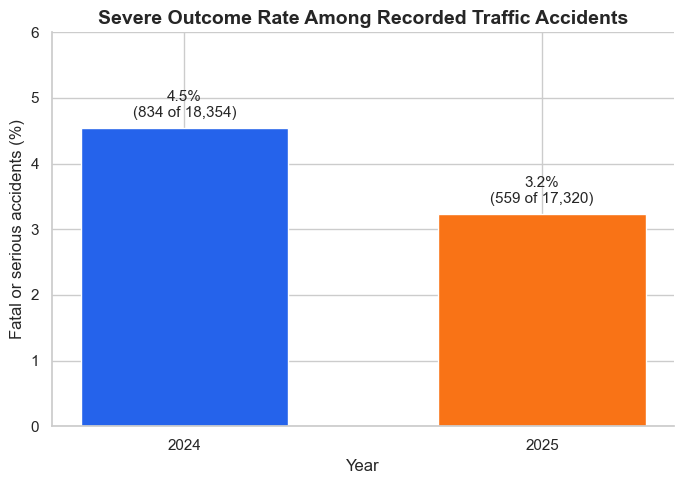

Saved: proposal_analysis\model_visualization_outputs\figures\01_severe_class_rate.png


In [7]:
class_distribution = pd.DataFrame({
    "Year": ["2024", "2025"],
    "Total accidents": [
        len(model_data24),
        len(model_data25)
    ],
    "Severe accidents": [
        int(model_data24["severe"].sum()),
        int(model_data25["severe"].sum())
    ]
})

class_distribution["Severe rate"] = (
    class_distribution["Severe accidents"]
    / class_distribution["Total accidents"]
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    class_distribution["Year"],
    class_distribution["Severe rate"] * 100,
    color=["#2563EB", "#F97316"],
    width=0.58
)

for bar, severe_count, total_count, rate in zip(
    bars,
    class_distribution["Severe accidents"],
    class_distribution["Total accidents"],
    class_distribution["Severe rate"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{rate:.1%}\n({severe_count:,} of {total_count:,})",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Severe Outcome Rate Among Recorded Traffic Accidents",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Year")
ax.set_ylabel("Fatal or serious accidents (%)")
ax.set_ylim(0, 6)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = FIGURE_DIR / "01_severe_class_rate.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

class_distribution.to_csv(
    TABLE_DIR / "class_distribution.csv",
    index=False
)

print("Saved:", figure_path)

In [8]:
X_2024 = model_data24[FULL_FEATURES].copy()
y_2024 = model_data24["severe"].copy()

X_2025 = model_data25[FULL_FEATURES].copy()
y_2025 = model_data25["severe"].copy()

assert len(X_2024) == 18354
assert len(X_2025) == 17320
assert y_2024.isin([0, 1]).all()
assert y_2025.isin([0, 1]).all()
assert list(X_2024.columns) == list(X_2025.columns)

data_split_summary = pd.DataFrame({
    "Dataset": [
        "2024 model development",
        "2025 independent temporal test"
    ],
    "Records": [
        len(y_2024),
        len(y_2025)
    ],
    "Severe outcomes": [
        int(y_2024.sum()),
        int(y_2025.sum())
    ],
    "Severe rate": [
        y_2024.mean(),
        y_2025.mean()
    ]
})

display(
    data_split_summary.style.format({
        "Severe rate": "{:.2%}"
    })
)

data_split_summary.to_csv(
    TABLE_DIR / "data_split_summary.csv",
    index=False
)

,Dataset,Records,Severe outcomes,Severe rate
0,2024 model development,18354,834,4.54%
1,2025 independent temporal test,17320,559,3.23%


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


CATEGORICAL_FEATURES = ROAD_CONTROL_FEATURES
NUMERIC_FEATURES = VEHICLE_NUMERIC_FEATURES


def make_preprocessor(feature_list):
    categorical_columns = [
        column for column in feature_list
        if column in CATEGORICAL_FEATURES
    ]

    numeric_columns = [
        column for column in feature_list
        if column in NUMERIC_FEATURES
    ]

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    transformers = []

    if categorical_columns:
        transformers.append(
            (
                "categorical",
                categorical_pipeline,
                categorical_columns
            )
        )

    if numeric_columns:
        transformers.append(
            (
                "numeric",
                numeric_pipeline,
                numeric_columns
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


full_preprocessor = make_preprocessor(FULL_FEATURES)

print("Categorical columns:", len(CATEGORICAL_FEATURES))
print("Numeric columns:", len(NUMERIC_FEATURES))
print("Preprocessor created successfully")

Categorical columns: 9
Numeric columns: 21
Preprocessor created successfully


In [10]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


def choose_f1_threshold(y_true, probability):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probability
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(
            precision[:-1] + recall[:-1],
            1e-15
        )
    )

    best_index = int(np.argmax(f1_values))
    return float(thresholds[best_index])


def evaluate_probability(y_true, probability, threshold):
    prediction = (
        np.asarray(probability) >= threshold
    ).astype(int)

    return {
        "PR_AUC": average_precision_score(
            y_true,
            probability
        ),
        "Recall": recall_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "Precision": precision_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "Balanced_accuracy": balanced_accuracy_score(
            y_true,
            prediction
        ),
        "Threshold": threshold
    }


fold_check = []

for fold_number, (_, validation_index) in enumerate(
    cv.split(X_2024, y_2024),
    start=1
):
    fold_target = y_2024.iloc[validation_index]

    fold_check.append({
        "Fold": fold_number,
        "Validation records": len(fold_target),
        "Severe outcomes": int(fold_target.sum()),
        "Severe rate": fold_target.mean()
    })

fold_check = pd.DataFrame(fold_check)

display(
    fold_check.style.format({
        "Severe rate": "{:.2%}"
    })
)

,Fold,Validation records,Severe outcomes,Severe rate
0,1,3671,167,4.55%
1,2,3671,167,4.55%
2,3,3671,167,4.55%
3,4,3671,167,4.55%
4,5,3670,166,4.52%


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict


dummy_X = np.zeros((len(y_2024), 1))

dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_oof_probability = cross_val_predict(
    dummy_model,
    dummy_X,
    y_2024,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

dummy_threshold = choose_f1_threshold(
    y_2024,
    dummy_oof_probability
)

dummy_metrics = evaluate_probability(
    y_2024,
    dummy_oof_probability,
    dummy_threshold
)

dummy_result = pd.DataFrame([
    {
        "Model": "Dummy baseline",
        "Feature set": "No predictive features",
        **dummy_metrics
    }
])

display(
    dummy_result.style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}",
        "Threshold": "{:.4f}"
    })
)

,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy,Threshold
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500,0.0454


In [12]:
from sklearn.linear_model import LogisticRegression


environment_logistic = Pipeline([
    (
        "preprocessor",
        make_preprocessor(ENVIRONMENT_FEATURES)
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE
        )
    )
])

environment_oof_probability = cross_val_predict(
    environment_logistic,
    model_data24[ENVIRONMENT_FEATURES],
    y_2024,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

environment_threshold = choose_f1_threshold(
    y_2024,
    environment_oof_probability
)

environment_metrics = evaluate_probability(
    y_2024,
    environment_oof_probability,
    environment_threshold
)

environment_result = pd.DataFrame([
    {
        "Model": "Weighted logistic regression",
        "Feature set": "Environment only",
        **environment_metrics
    }
])

cv_results = pd.concat(
    [dummy_result, environment_result],
    ignore_index=True
)

display(
    cv_results[
        [
            "Model",
            "Feature set",
            "PR_AUC",
            "Recall",
            "Precision",
            "F1",
            "Balanced_accuracy"
        ]
    ].style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}"
    })
)

,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500
1,Weighted logistic regression,Environment only,0.0450,0.947,0.047,0.089,0.514


In [13]:
road_logistic = Pipeline([
    (
        "preprocessor",
        make_preprocessor(ROAD_CONTROL_FEATURES)
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE
        )
    )
])

road_oof_probability = cross_val_predict(
    road_logistic,
    model_data24[ROAD_CONTROL_FEATURES],
    y_2024,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

road_threshold = choose_f1_threshold(
    y_2024,
    road_oof_probability
)

road_metrics = evaluate_probability(
    y_2024,
    road_oof_probability,
    road_threshold
)

road_result = pd.DataFrame([
    {
        "Model": "Weighted logistic regression",
        "Feature set": "Environment + road controls",
        **road_metrics
    }
])

cv_results = pd.concat(
    [
        dummy_result,
        environment_result,
        road_result
    ],
    ignore_index=True
)

display(
    cv_results[
        [
            "Model",
            "Feature set",
            "PR_AUC",
            "Recall",
            "Precision",
            "F1",
            "Balanced_accuracy"
        ]
    ].style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}"
    })
)

,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500
1,Weighted logistic regression,Environment only,0.0450,0.947,0.047,0.089,0.514
2,Weighted logistic regression,Environment + road controls,0.1109,0.293,0.139,0.188,0.603


In [14]:
full_logistic = Pipeline([
    (
        "preprocessor",
        make_preprocessor(FULL_FEATURES)
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            solver="lbfgs",
            random_state=RANDOM_STATE
        )
    )
])

full_logistic_oof_probability = cross_val_predict(
    full_logistic,
    X_2024,
    y_2024,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

full_logistic_threshold = choose_f1_threshold(
    y_2024,
    full_logistic_oof_probability
)

full_logistic_metrics = evaluate_probability(
    y_2024,
    full_logistic_oof_probability,
    full_logistic_threshold
)

full_logistic_result = pd.DataFrame([
    {
        "Model": "Weighted logistic regression",
        "Feature set": "Full model with vehicle features",
        **full_logistic_metrics
    }
])

cv_results = pd.concat(
    [
        dummy_result,
        environment_result,
        road_result,
        full_logistic_result
    ],
    ignore_index=True
)

display(
    cv_results[
        [
            "Model",
            "Feature set",
            "PR_AUC",
            "Recall",
            "Precision",
            "F1",
            "Balanced_accuracy"
        ]
    ].style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}"
    })
)

,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500
1,Weighted logistic regression,Environment only,0.0450,0.947,0.047,0.089,0.514
2,Weighted logistic regression,Environment + road controls,0.1109,0.293,0.139,0.188,0.603
3,Weighted logistic regression,Full model with vehicle features,0.1289,0.392,0.147,0.214,0.642


In [15]:
from sklearn.ensemble import RandomForestClassifier


random_forest = Pipeline([
    (
        "preprocessor",
        make_preprocessor(FULL_FEATURES)
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=400,
            max_depth=12,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

random_forest_oof_probability = cross_val_predict(
    random_forest,
    X_2024,
    y_2024,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

random_forest_threshold = choose_f1_threshold(
    y_2024,
    random_forest_oof_probability
)

random_forest_metrics = evaluate_probability(
    y_2024,
    random_forest_oof_probability,
    random_forest_threshold
)

random_forest_result = pd.DataFrame([
    {
        "Model": "Random forest",
        "Feature set": "Full model with vehicle features",
        **random_forest_metrics
    }
])

cv_results = pd.concat(
    [
        dummy_result,
        environment_result,
        road_result,
        full_logistic_result,
        random_forest_result
    ],
    ignore_index=True
)

display(
    cv_results[
        [
            "Model",
            "Feature set",
            "PR_AUC",
            "Recall",
            "Precision",
            "F1",
            "Balanced_accuracy"
        ]
    ].style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}"
    })
)

,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500
1,Weighted logistic regression,Environment only,0.0450,0.947,0.047,0.089,0.514
2,Weighted logistic regression,Environment + road controls,0.1109,0.293,0.139,0.188,0.603
3,Weighted logistic regression,Full model with vehicle features,0.1289,0.392,0.147,0.214,0.642
4,Random forest,Full model with vehicle features,0.1151,0.324,0.133,0.188,0.612


In [16]:
from catboost import CatBoostClassifier


def prepare_catboost_data(frame):
    result = frame[FULL_FEATURES].copy()

    for column in CATEGORICAL_FEATURES:
        result[column] = (
            result[column]
            .fillna("Missing")
            .astype(str)
        )

    for column in NUMERIC_FEATURES:
        result[column] = pd.to_numeric(
            result[column],
            errors="coerce"
        )

    return result


catboost_X_2024 = prepare_catboost_data(model_data24)

catboost_oof_probability = np.zeros(len(y_2024))
catboost_best_iterations = []

for fold_number, (train_index, validation_index) in enumerate(
    cv.split(catboost_X_2024, y_2024),
    start=1
):
    X_train_fold = catboost_X_2024.iloc[train_index]
    y_train_fold = y_2024.iloc[train_index]

    X_valid_fold = catboost_X_2024.iloc[validation_index]
    y_valid_fold = y_2024.iloc[validation_index]

    fold_model = CatBoostClassifier(
        iterations=600,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        eval_metric="PRAUC",
        auto_class_weights="Balanced",
        random_seed=RANDOM_STATE + fold_number,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    fold_model.fit(
        X_train_fold,
        y_train_fold,
        cat_features=CATEGORICAL_FEATURES,
        eval_set=(X_valid_fold, y_valid_fold),
        early_stopping_rounds=60,
        use_best_model=True
    )

    catboost_oof_probability[validation_index] = (
        fold_model.predict_proba(X_valid_fold)[:, 1]
    )

    best_iteration = fold_model.get_best_iteration() + 1
    catboost_best_iterations.append(best_iteration)

    print(
        f"Fold {fold_number} completed; "
        f"best iteration = {best_iteration}"
    )


catboost_threshold = choose_f1_threshold(
    y_2024,
    catboost_oof_probability
)

catboost_metrics = evaluate_probability(
    y_2024,
    catboost_oof_probability,
    catboost_threshold
)

catboost_result = pd.DataFrame([
    {
        "Model": "CatBoost",
        "Feature set": "Full model with vehicle features",
        **catboost_metrics
    }
])

cv_results = pd.concat(
    [
        dummy_result,
        environment_result,
        road_result,
        full_logistic_result,
        random_forest_result,
        catboost_result
    ],
    ignore_index=True
)

CATBOOST_FINAL_ITERATIONS = int(
    np.median(catboost_best_iterations)
)

print(
    "Final CatBoost iterations:",
    CATBOOST_FINAL_ITERATIONS
)

display(
    cv_results[
        [
            "Model",
            "Feature set",
            "PR_AUC",
            "Recall",
            "Precision",
            "F1",
            "Balanced_accuracy"
        ]
    ].style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}"
    })
)

Fold 1 completed; best iteration = 235
Fold 2 completed; best iteration = 48
Fold 3 completed; best iteration = 194
Fold 4 completed; best iteration = 1
Fold 5 completed; best iteration = 150
Final CatBoost iterations: 150


,Model,Feature set,PR_AUC,Recall,Precision,F1,Balanced_accuracy
0,Dummy baseline,No predictive features,0.0454,1.000,0.045,0.087,0.500
1,Weighted logistic regression,Environment only,0.0450,0.947,0.047,0.089,0.514
2,Weighted logistic regression,Environment + road controls,0.1109,0.293,0.139,0.188,0.603
3,Weighted logistic regression,Full model with vehicle features,0.1289,0.392,0.147,0.214,0.642
4,Random forest,Full model with vehicle features,0.1151,0.324,0.133,0.188,0.612
5,CatBoost,Full model with vehicle features,0.1244,0.622,0.114,0.192,0.696


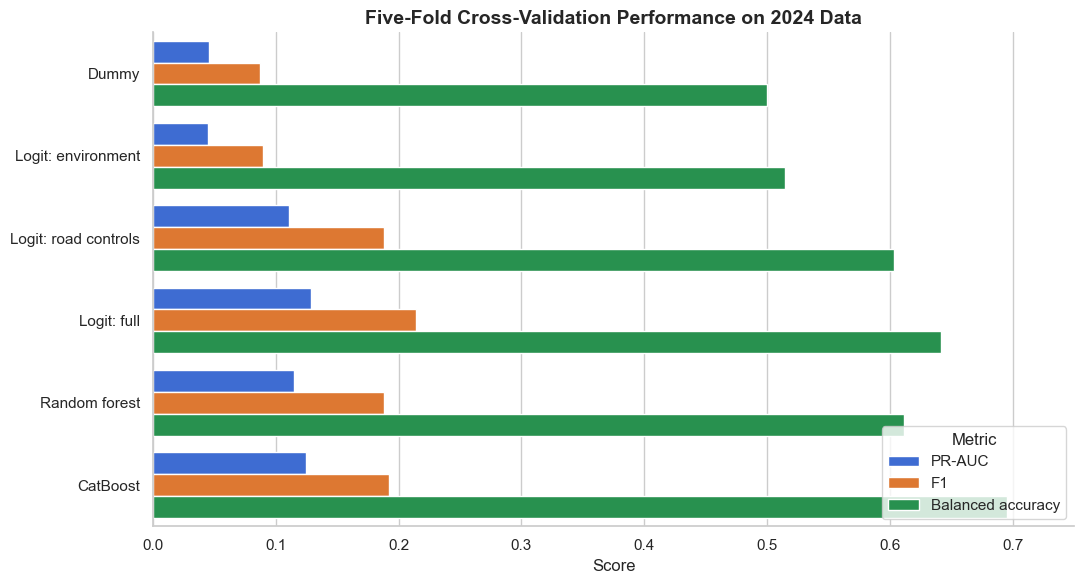

Saved: proposal_analysis\model_visualization_outputs\figures\02_cross_validation_model_comparison.png


In [17]:
model_labels = [
    "Dummy",
    "Logit: environment",
    "Logit: road controls",
    "Logit: full",
    "Random forest",
    "CatBoost"
]

plot_results = cv_results.copy()
plot_results["Label"] = model_labels

metrics_to_plot = [
    "PR_AUC",
    "F1",
    "Balanced_accuracy"
]

plot_long = plot_results.melt(
    id_vars="Label",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

metric_name_map = {
    "PR_AUC": "PR-AUC",
    "F1": "F1",
    "Balanced_accuracy": "Balanced accuracy"
}

plot_long["Metric"] = plot_long["Metric"].map(
    metric_name_map
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=plot_long,
    y="Label",
    x="Score",
    hue="Metric",
    palette=["#2563EB", "#F97316", "#16A34A"],
    ax=ax
)

ax.set_title(
    "Five-Fold Cross-Validation Performance on 2024 Data",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 0.75)
ax.legend(
    title="Metric",
    loc="lower right"
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "02_cross_validation_model_comparison.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

cv_results.to_csv(
    TABLE_DIR / "cross_validation_results.csv",
    index=False
)

print("Saved:", figure_path)

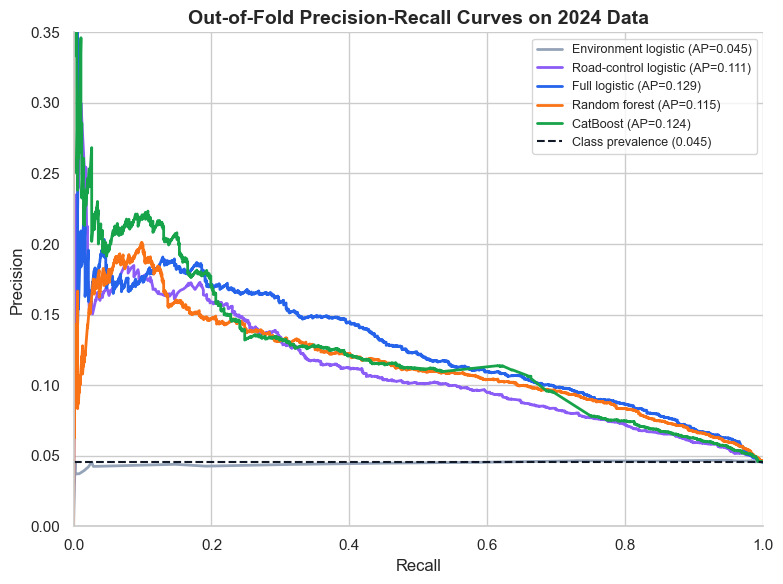

Saved: proposal_analysis\model_visualization_outputs\figures\03_cross_validation_pr_curves.png


In [18]:
oof_probabilities = {
    "Environment logistic":
        environment_oof_probability,
    "Road-control logistic":
        road_oof_probability,
    "Full logistic":
        full_logistic_oof_probability,
    "Random forest":
        random_forest_oof_probability,
    "CatBoost":
        catboost_oof_probability
}

curve_colors = {
    "Environment logistic": "#94A3B8",
    "Road-control logistic": "#8B5CF6",
    "Full logistic": "#2563EB",
    "Random forest": "#F97316",
    "CatBoost": "#16A34A"
}

fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probability in oof_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_2024,
        probability
    )

    pr_auc = average_precision_score(
        y_2024,
        probability
    )

    ax.plot(
        recall,
        precision,
        linewidth=2,
        color=curve_colors[model_name],
        label=f"{model_name} (AP={pr_auc:.3f})"
    )

baseline_rate = y_2024.mean()

ax.axhline(
    baseline_rate,
    color="#111827",
    linestyle="--",
    linewidth=1.5,
    label=f"Class prevalence ({baseline_rate:.3f})"
)

ax.set_title(
    "Out-of-Fold Precision-Recall Curves on 2024 Data",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.35)
ax.legend(
    loc="upper right",
    fontsize=9
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "03_cross_validation_pr_curves.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved:", figure_path)

In [19]:
from sklearn.base import clone


selected_model = clone(full_logistic)

selected_model.fit(
    X_2024,
    y_2024
)

test_probability = selected_model.predict_proba(
    X_2025
)[:, 1]

test_metrics = evaluate_probability(
    y_2025,
    test_probability,
    full_logistic_threshold
)

test_result = pd.DataFrame([
    {
        "Model": "Weighted logistic regression",
        "Dataset": "2025 independent temporal test",
        **test_metrics
    }
])

display(
    test_result.style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}",
        "Threshold": "{:.4f}"
    })
)

test_prediction = pd.DataFrame({
    "Serial": model_data25["Serial"],
    "True severe outcome": y_2025,
    "Predicted probability": test_probability,
    "Predicted severe outcome": (
        test_probability >= full_logistic_threshold
    ).astype(int)
})

test_result.to_csv(
    TABLE_DIR / "2025_temporal_test_metrics.csv",
    index=False
)

test_prediction.to_csv(
    TABLE_DIR / "2025_temporal_test_predictions.csv",
    index=False
)

,Model,Dataset,PR_AUC,Recall,Precision,F1,Balanced_accuracy,Threshold
0,Weighted logistic regression,2025 independent temporal test,0.1031,0.379,0.103,0.163,0.635,0.7062


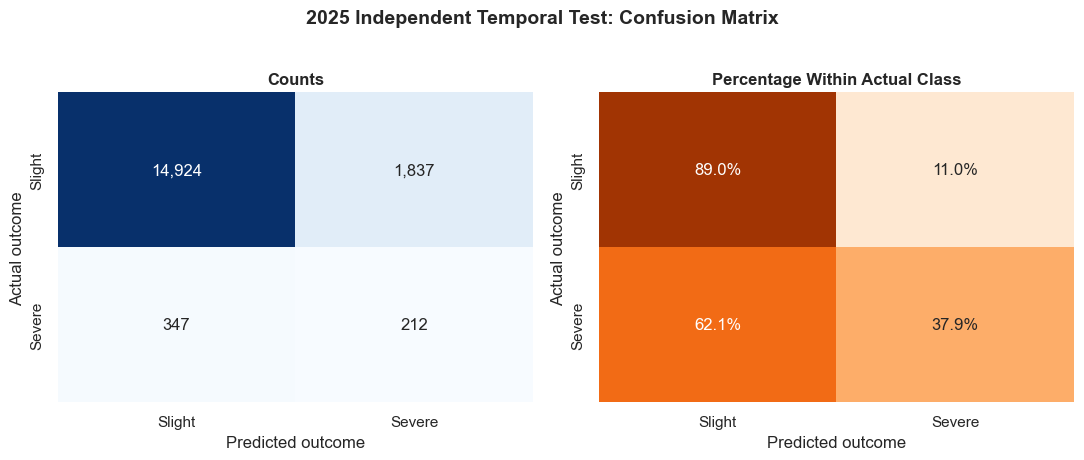

Saved: proposal_analysis\model_visualization_outputs\figures\04_2025_temporal_test_confusion_matrix.png


In [20]:
from sklearn.metrics import confusion_matrix


test_class_prediction = (
    test_probability >= full_logistic_threshold
).astype(int)

confusion_counts = confusion_matrix(
    y_2025,
    test_class_prediction
)

confusion_row_rate = confusion_counts / (
    confusion_counts.sum(axis=1, keepdims=True)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.5)
)

sns.heatmap(
    confusion_counts,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Slight", "Severe"],
    yticklabels=["Slight", "Severe"],
    ax=axes[0]
)

axes[0].set_title(
    "Counts",
    weight="bold"
)
axes[0].set_xlabel("Predicted outcome")
axes[0].set_ylabel("Actual outcome")

sns.heatmap(
    confusion_row_rate,
    annot=True,
    fmt=".1%",
    cmap="Oranges",
    cbar=False,
    vmin=0,
    vmax=1,
    xticklabels=["Slight", "Severe"],
    yticklabels=["Slight", "Severe"],
    ax=axes[1]
)

axes[1].set_title(
    "Percentage Within Actual Class",
    weight="bold"
)
axes[1].set_xlabel("Predicted outcome")
axes[1].set_ylabel("Actual outcome")

fig.suptitle(
    "2025 Independent Temporal Test: Confusion Matrix",
    fontsize=14,
    weight="bold",
    y=1.02
)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "04_2025_temporal_test_confusion_matrix.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved:", figure_path)

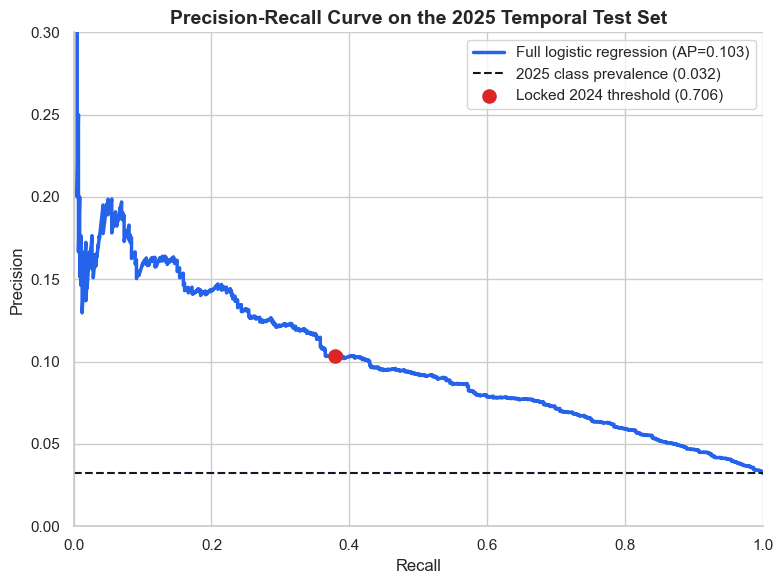

Saved: proposal_analysis\model_visualization_outputs\figures\05_2025_temporal_test_pr_curve.png


In [21]:
test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        y_2025,
        test_probability
    )
)

test_pr_auc = average_precision_score(
    y_2025,
    test_probability
)

test_baseline_rate = y_2025.mean()

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    test_recall_curve,
    test_precision_curve,
    color="#2563EB",
    linewidth=2.5,
    label=(
        "Full logistic regression "
        f"(AP={test_pr_auc:.3f})"
    )
)

ax.axhline(
    test_baseline_rate,
    color="#111827",
    linestyle="--",
    linewidth=1.5,
    label=(
        "2025 class prevalence "
        f"({test_baseline_rate:.3f})"
    )
)

ax.scatter(
    test_metrics["Recall"],
    test_metrics["Precision"],
    s=90,
    color="#DC2626",
    zorder=5,
    label=(
        "Locked 2024 threshold "
        f"({full_logistic_threshold:.3f})"
    )
)

ax.set_title(
    "Precision-Recall Curve on the 2025 Temporal Test Set",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.30)
ax.legend(loc="upper right")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "05_2025_temporal_test_pr_curve.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved:", figure_path)

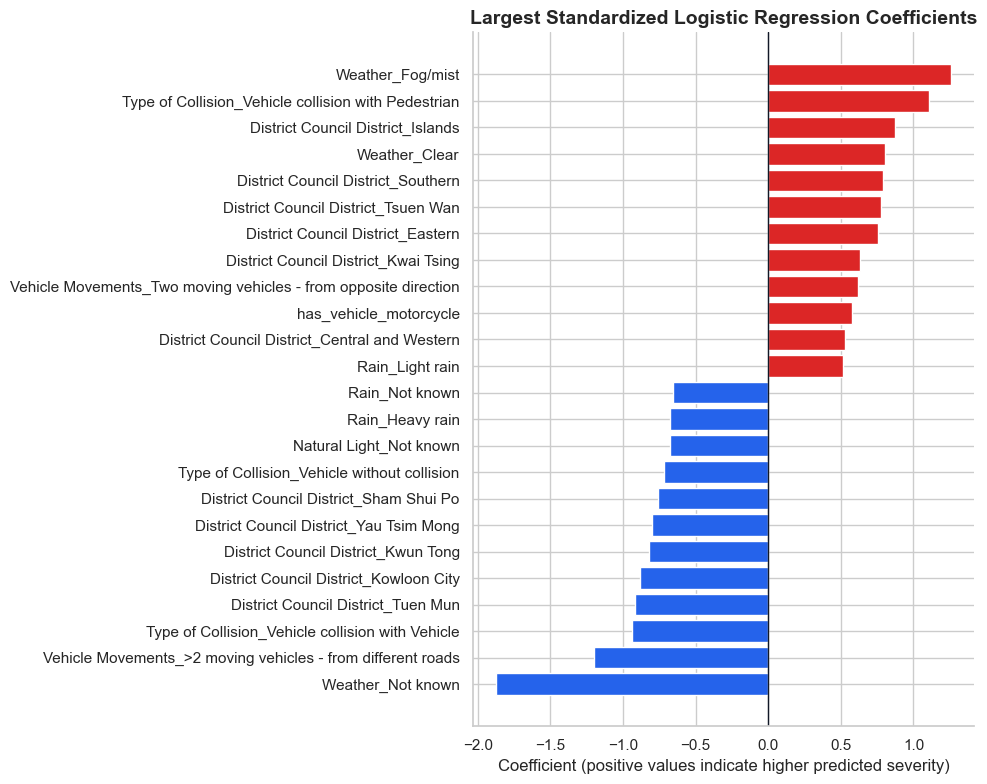

Saved: proposal_analysis\model_visualization_outputs\figures\06_logistic_regression_coefficients.png


In [22]:
fitted_preprocessor = selected_model.named_steps[
    "preprocessor"
]
fitted_logistic = selected_model.named_steps["model"]

encoded_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

clean_feature_names = [
    name.replace("categorical__", "")
        .replace("numeric__", "")
    for name in encoded_feature_names
]

coefficient_table = pd.DataFrame({
    "Feature": clean_feature_names,
    "Coefficient": fitted_logistic.coef_[0]
})

largest_negative = coefficient_table.nsmallest(
    12,
    "Coefficient"
)

largest_positive = coefficient_table.nlargest(
    12,
    "Coefficient"
)

coefficient_plot = pd.concat(
    [largest_negative, largest_positive]
).drop_duplicates()

coefficient_plot = coefficient_plot.sort_values(
    "Coefficient"
)

colors = np.where(
    coefficient_plot["Coefficient"] >= 0,
    "#DC2626",
    "#2563EB"
)

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    coefficient_plot["Feature"],
    coefficient_plot["Coefficient"],
    color=colors
)

ax.axvline(
    0,
    color="#111827",
    linewidth=1
)

ax.set_title(
    "Largest Standardized Logistic Regression Coefficients",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel(
    "Coefficient "
    "(positive values indicate higher predicted severity)"
)
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "06_logistic_regression_coefficients.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

coefficient_table.sort_values(
    "Coefficient",
    ascending=False
).to_csv(
    TABLE_DIR / "logistic_regression_coefficients.csv",
    index=False
)

print("Saved:", figure_path)

In [23]:
final_catboost = CatBoostClassifier(
    iterations=CATBOOST_FINAL_ITERATIONS,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

final_catboost.fit(
    catboost_X_2024,
    y_2024,
    cat_features=CATEGORICAL_FEATURES
)

catboost_X_2025 = prepare_catboost_data(
    model_data25
)

catboost_test_probability = (
    final_catboost.predict_proba(
        catboost_X_2025
    )[:, 1]
)

catboost_test_metrics = evaluate_probability(
    y_2025,
    catboost_test_probability,
    catboost_threshold
)

temporal_model_comparison = pd.DataFrame([
    {
        "Model": "Weighted logistic regression",
        **test_metrics
    },
    {
        "Model": "CatBoost",
        **catboost_test_metrics
    }
])

display(
    temporal_model_comparison.style.format({
        "PR_AUC": "{:.4f}",
        "Recall": "{:.3f}",
        "Precision": "{:.3f}",
        "F1": "{:.3f}",
        "Balanced_accuracy": "{:.3f}",
        "Threshold": "{:.4f}"
    })
)

temporal_model_comparison.to_csv(
    TABLE_DIR / "2025_temporal_model_comparison.csv",
    index=False
)

,Model,PR_AUC,Recall,Precision,F1,Balanced_accuracy,Threshold
0,Weighted logistic regression,0.1031,0.379,0.103,0.163,0.635,0.7062
1,CatBoost,0.0967,0.639,0.077,0.138,0.692,0.5084


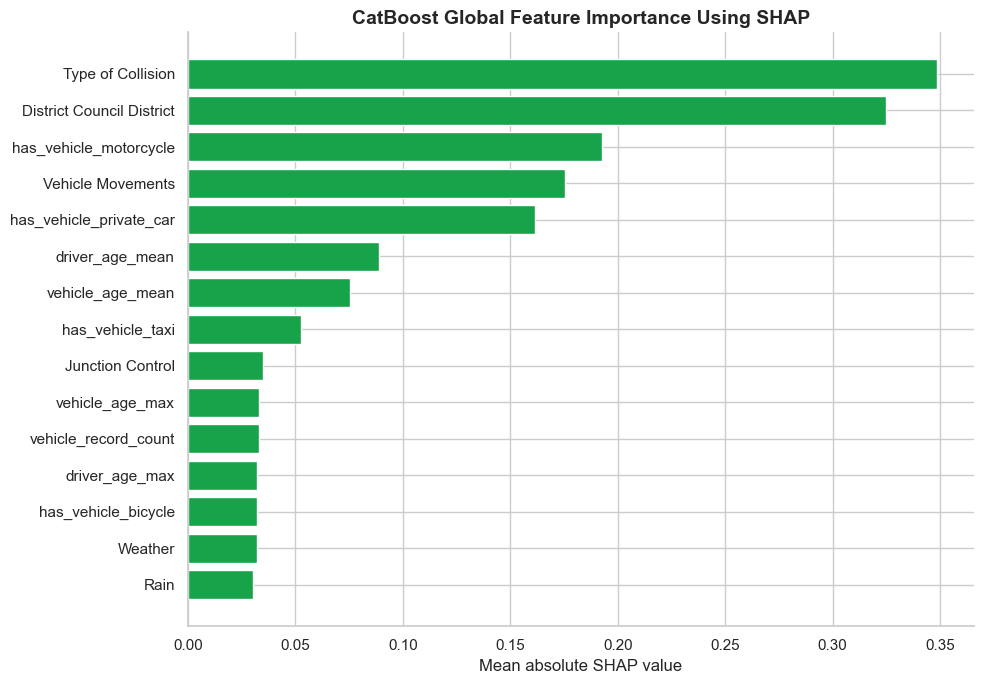

Saved: proposal_analysis\model_visualization_outputs\figures\07_catboost_shap_importance.png


In [24]:
from catboost import Pool


shap_sample = catboost_X_2024.sample(
    n=min(2000, len(catboost_X_2024)),
    random_state=RANDOM_STATE
)

shap_pool = Pool(
    shap_sample,
    cat_features=CATEGORICAL_FEATURES
)

# The final column is CatBoost's expected value.
shap_matrix = final_catboost.get_feature_importance(
    shap_pool,
    type="ShapValues"
)

shap_values = shap_matrix[:, :-1]

shap_importance = pd.DataFrame({
    "Feature": FULL_FEATURES,
    "Mean absolute SHAP value": (
        np.abs(shap_values).mean(axis=0)
    )
}).sort_values(
    "Mean absolute SHAP value",
    ascending=False
)

top_shap = shap_importance.head(15).sort_values(
    "Mean absolute SHAP value"
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_shap["Feature"],
    top_shap["Mean absolute SHAP value"],
    color="#16A34A"
)

ax.set_title(
    "CatBoost Global Feature Importance Using SHAP",
    fontsize=14,
    weight="bold"
)
ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "07_catboost_shap_importance.png"
)
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

shap_importance.to_csv(
    TABLE_DIR / "catboost_shap_importance.csv",
    index=False
)

print("Saved:", figure_path)

In [25]:
import json
import joblib


MODEL_DIR = OUTPUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

logistic_model_path = (
    MODEL_DIR / "selected_logistic_model.joblib"
)

catboost_model_path = (
    MODEL_DIR / "catboost_explanation_model.cbm"
)

joblib.dump(
    selected_model,
    logistic_model_path
)

final_catboost.save_model(
    catboost_model_path
)

model_metadata = {
    "selected_primary_model":
        "Weighted logistic regression",
    "selection_metric":
        "2024 five-fold out-of-fold PR-AUC",
    "selected_threshold":
        float(full_logistic_threshold),
    "2024_cross_validation_PR_AUC":
        float(full_logistic_metrics["PR_AUC"]),
    "2025_temporal_test_PR_AUC":
        float(test_metrics["PR_AUC"]),
    "catboost_role":
        "Secondary nonlinear model for SHAP explanation",
    "random_state":
        RANDOM_STATE
}

metadata_path = MODEL_DIR / "model_metadata.json"

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        model_metadata,
        file,
        indent=2
    )

print("Saved:", logistic_model_path)
print("Saved:", catboost_model_path)
print("Saved:", metadata_path)

Saved: proposal_analysis\model_visualization_outputs\models\selected_logistic_model.joblib
Saved: proposal_analysis\model_visualization_outputs\models\catboost_explanation_model.cbm
Saved: proposal_analysis\model_visualization_outputs\models\model_metadata.json
